# 实验三 B：卷积神经网络多层特征可视化

使用 ImageNet 预训练 ResNet-18，提取 `layer1`、`layer2`、`layer3` 和 `layer4` 的输出，比较浅层到深层特征的空间结构与稀疏性。复用实验三 A 的五张图片，以金鱼图片展示各层的代表通道，再对五张图片统计全部通道的零激活比例。

图片来源：[ImageNet sample images](https://github.com/EliSchwartz/imagenet-sample-images)。首次独立运行时会自动下载所需图片和预训练权重。

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision.models import resnet18, ResNet18_Weights

ROOT = Path.cwd()
if ROOT.name != "exp3" and (ROOT / "exp3").is_dir():
    ROOT = ROOT / "exp3"
DATA_DIR = ROOT / "data" / "gradcam_samples"
RESULT_DIR = ROOT / "results" / "exp3B"
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(ROOT / ".cache" / "torch"))

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("运行设备：", device)

运行设备： cpu


## 1. 模型与特征层

ResNet-18 包含初始卷积、四组残差模块、全局平均池化和全连接分类层。每组残差模块含两个 BasicBlock，每个 BasicBlock 含两个 3×3 卷积。本实验选取四组残差模块的输出，均为残差相加并经过 ReLU 后的非负特征。

对 224×224 的输入，四层输出依次为 64×56×56、128×28×28、256×14×14 和 512×7×7。越靠后的层空间分辨率越低、通道数越多，每个位置能够综合更大范围的信息。

In [2]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()
preprocess = weights.transforms()
class_names = weights.meta["categories"]
layer_names = ["layer1", "layer2", "layer3", "layer4"]

samples = [
    ("goldfish", "n01443537_goldfish.JPEG"),
    ("golden retriever", "n02099601_golden_retriever.JPEG"),
    ("tabby", "n02123045_tabby.JPEG"),
    ("airliner", "n02690373_airliner.JPEG"),
    ("school bus", "n04146614_school_bus.JPEG"),
]
base_url = "https://raw.githubusercontent.com/EliSchwartz/imagenet-sample-images/master/"
for label, filename in samples:
    path = DATA_DIR / filename
    if not path.exists():
        urlretrieve(base_url + filename, path)

print(model)
print("观察层：", layer_names)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 2. 提取各层特征并统计稀疏性

通过 forward hook 保存四层输出，使用 `torch.no_grad()` 完成前向传播，不训练或修改模型。稀疏性定义为特征值不大于 1e-6 的元素占该层全部元素的比例，作为 ReLU 后零激活比例的数值近似。统计使用所有通道，而不是只使用后面展示的通道。

In [3]:
def extract_features(input_tensor):
    features = {}
    handles = []

    def save_output(name):
        def hook(module, inputs, output):
            features[name] = output[0].detach().cpu()
        return hook

    try:
        for name in layer_names:
            layer = getattr(model, name)
            handles.append(layer.register_forward_hook(save_output(name)))
        with torch.no_grad():
            logits = model(input_tensor)
        return features, logits.softmax(dim=1)[0].cpu()
    finally:
        for handle in handles:
            handle.remove()


mean = torch.tensor(preprocess.mean).view(3, 1, 1)
std = torch.tensor(preprocess.std).view(3, 1, 1)
all_features = {}
originals = {}
records = []
predictions = []

for label, filename in samples:
    with Image.open(DATA_DIR / filename) as image:
        input_tensor = preprocess(image.convert("RGB")).unsqueeze(0).to(device)
    features, probabilities = extract_features(input_tensor)
    all_features[label] = features
    original = input_tensor[0].detach().cpu() * std + mean
    originals[label] = original.permute(1, 2, 0).numpy().clip(0, 1)
    pred_id = probabilities.argmax().item()
    predictions.append({"sample_class": label,
                        "predicted_class": class_names[pred_id],
                        "probability": float(probabilities[pred_id])})

    for name, feature in features.items():
        channels, height, width = feature.shape
        records.append({
            "sample_class": label, "layer": name,
            "channels": channels, "height": height, "width": width,
            "zero_fraction": float((feature <= 1e-6).float().mean()),
            "mean_activation": float(feature.mean()),
        })

stats_df = pd.DataFrame(records)
summary_df = stats_df.groupby("layer", sort=False).agg(
    channels=("channels", "first"), height=("height", "first"),
    width=("width", "first"), mean_zero_fraction=("zero_fraction", "mean"),
    mean_activation=("mean_activation", "mean"),
).reset_index()
stats_df.to_csv(RESULT_DIR / "feature_statistics.csv", index=False, encoding="utf-8-sig")
summary_df.to_csv(RESULT_DIR / "layer_summary.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(predictions).to_csv(RESULT_DIR / "predictions.csv", index=False, encoding="utf-8-sig")
print(pd.DataFrame(predictions).to_string(index=False))
summary_df

    sample_class  predicted_class  probability
        goldfish         goldfish     0.995492
golden retriever golden retriever     0.585482
           tabby     Egyptian cat     0.465141
        airliner         airliner     0.838542
      school bus       school bus     0.883465


,layer,channels,height,width,mean_zero_fraction,mean_activation
0,layer1,64,56,56,0.234110,0.492366
1,layer2,128,28,28,0.492554,0.180903
2,layer3,256,14,14,0.552710,0.119988
3,layer4,512,7,7,0.451419,0.913517


## 3. 各层通道的特征图

以金鱼为例，每层按通道的空间平均响应从高到低选取前 8 个通道。各特征图除以自身最大值后显示，颜色表示该通道内部的相对响应，不能据此比较不同通道的绝对强弱。标题保留通道编号和原始平均响应，所有统计仍使用完整特征。

不同层的通道没有一一对应关系。观察时主要比较细节、响应范围和空间分辨率，不把某个通道直接命名为确定的语义。

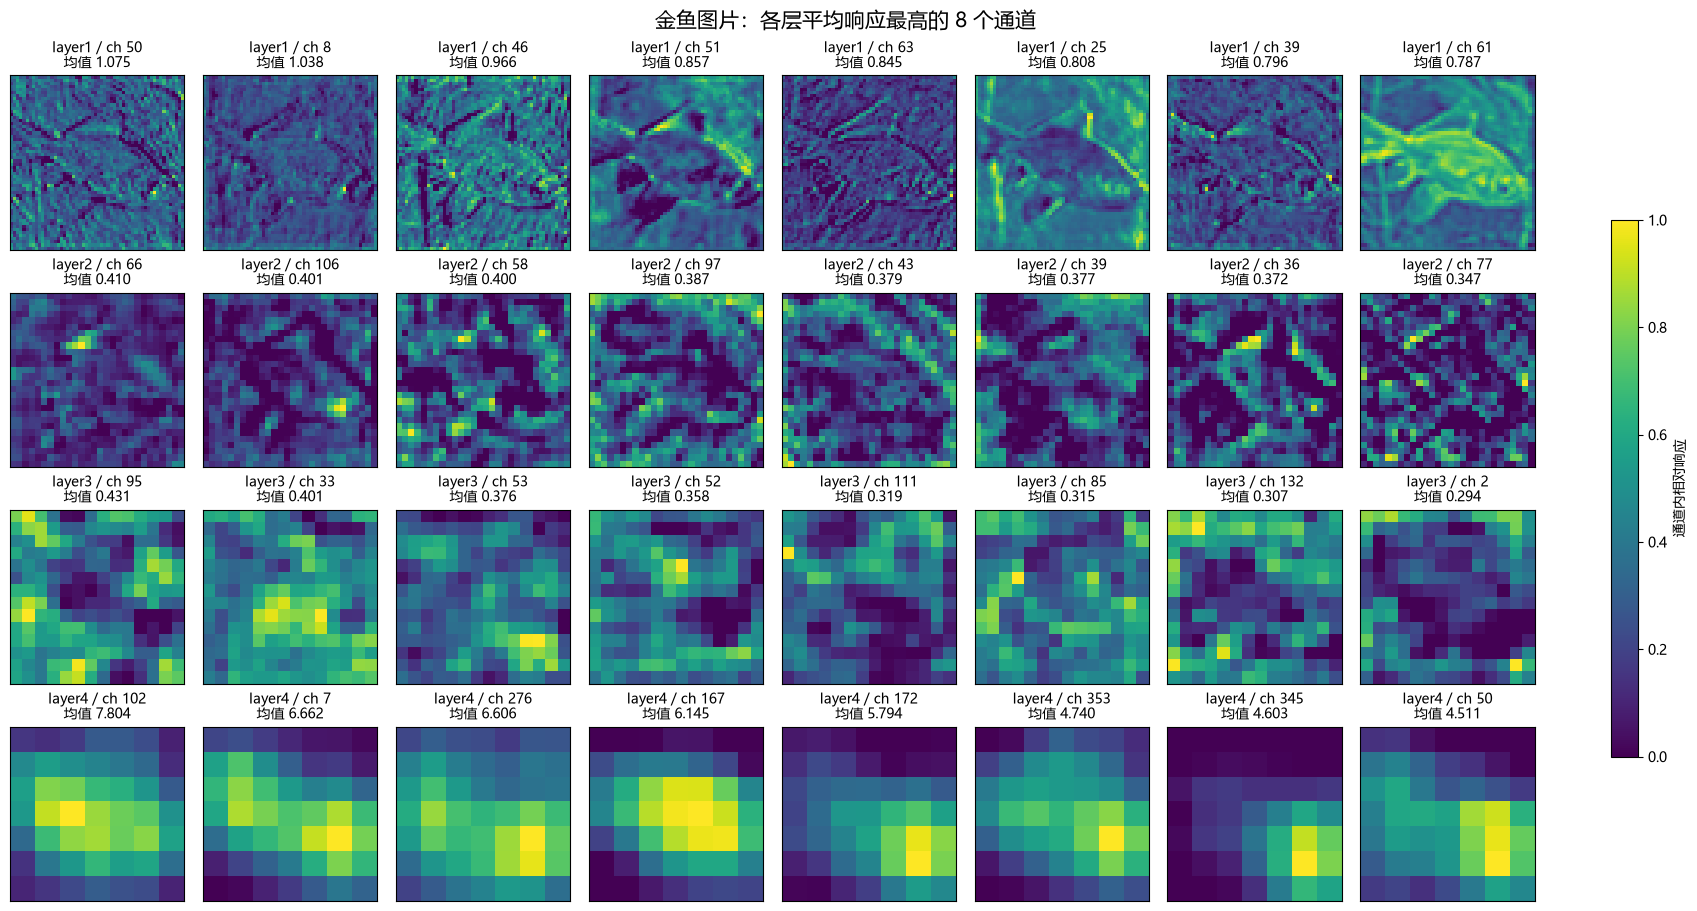

In [4]:
example_label = "goldfish"
TOP_K = 8
fig, axes = plt.subplots(len(layer_names), TOP_K, figsize=(17, 9),
                         constrained_layout=True)
selected_records = []

for row, name in enumerate(layer_names):
    feature = all_features[example_label][name]
    channel_means = feature.mean(dim=(1, 2))
    selected = channel_means.argsort(descending=True)[:TOP_K].tolist()
    for col, channel_id in enumerate(selected):
        fmap = feature[channel_id].numpy()
        normalized = fmap / max(float(fmap.max()), 1e-8)
        im = axes[row, col].imshow(normalized, cmap="viridis", vmin=0, vmax=1,
                                    interpolation="nearest")
        axes[row, col].set_title(
            f"{name} / ch {channel_id}\n均值 {channel_means[channel_id]:.3f}", fontsize=10)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        selected_records.append({"layer": name, "channel": channel_id,
                                 "mean_activation": float(channel_means[channel_id])})

fig.suptitle("金鱼图片：各层平均响应最高的 8 个通道", fontsize=15)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.65, label="通道内相对响应")
fig.savefig(RESULT_DIR / "feature_channels.png", dpi=180, bbox_inches="tight")
plt.show()
pd.DataFrame(selected_records).to_csv(
    RESULT_DIR / "selected_channels.csv", index=False, encoding="utf-8-sig")

## 4. 原图与多层平均响应对比

将每层所有通道求平均，得到空间响应图，并在每幅图内部归一化。用原始网格显示这些响应图，便于看出分辨率变化。通道平均响应没有类别权重，不能当作上一实验的 Grad-CAM，也不保证突出当前预测类别的目标。

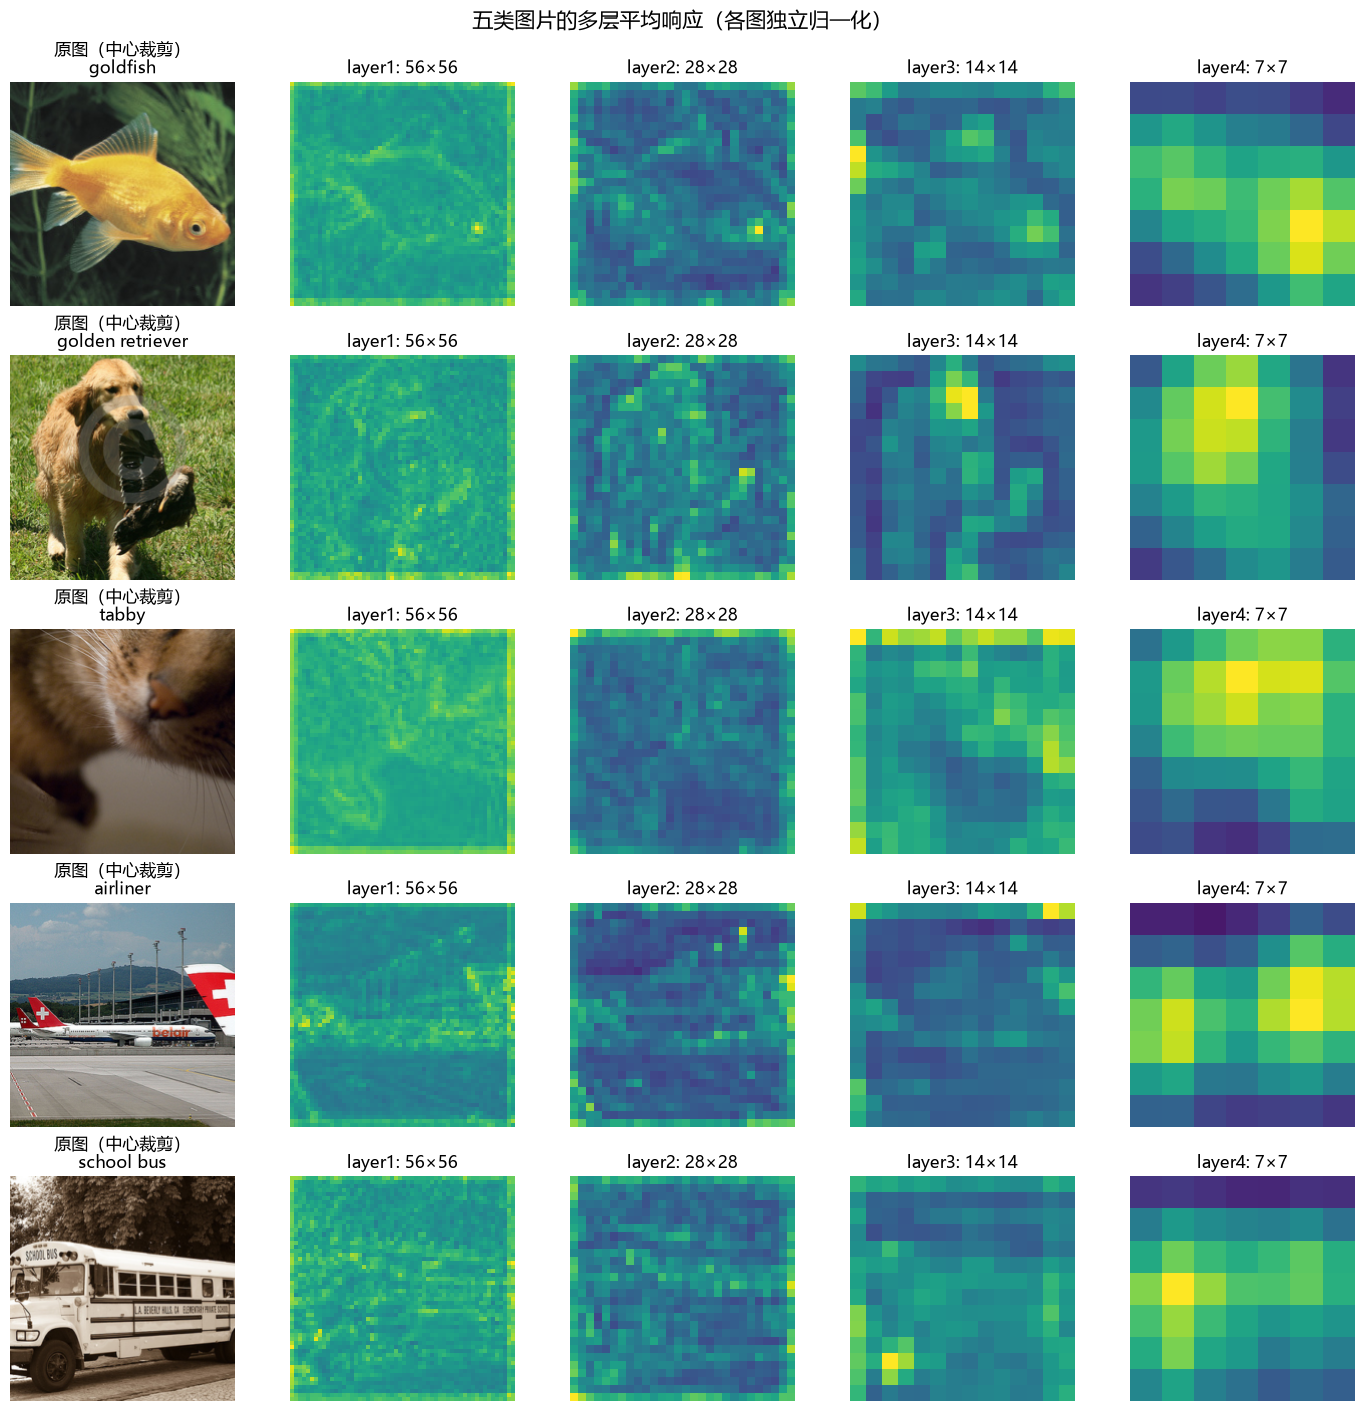

In [5]:
fig, axes = plt.subplots(len(samples), len(layer_names) + 1,
                         figsize=(14, 14), constrained_layout=True)

for row, (label, _) in enumerate(samples):
    axes[row, 0].imshow(originals[label])
    axes[row, 0].set_title(f"原图（中心裁剪）\n{label}")
    for col, name in enumerate(layer_names, start=1):
        feature = all_features[label][name]
        mean_map = feature.mean(dim=0).numpy()
        normalized = mean_map / max(float(mean_map.max()), 1e-8)
        axes[row, col].imshow(normalized, cmap="viridis", vmin=0, vmax=1,
                               interpolation="nearest")
        axes[row, col].set_title(f"{name}: {feature.shape[1]}×{feature.shape[2]}")
    for ax in axes[row]:
        ax.axis("off")

fig.suptitle("五类图片的多层平均响应（各图独立归一化）", fontsize=15)
fig.savefig(RESULT_DIR / "feature_mean_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. 特征稀疏性比较

绘制每张图片在四层上的零激活比例，并给出五张图片的均值。稀疏性变化需要根据实际结果判断，不预设它一定随深度单调增加；残差连接、输入内容和目标层位置都会影响结果。这五张图只是小规模观察，不能代表整个数据集。

结合通道图和统计结果，分析浅层的局部细节与深层较粗的空间响应。深层特征经过全局平均池化后输入分类层，可以综合不同通道的信息完成类别判断，但单凭这些可视化不能确定每个通道的语义或分类贡献。

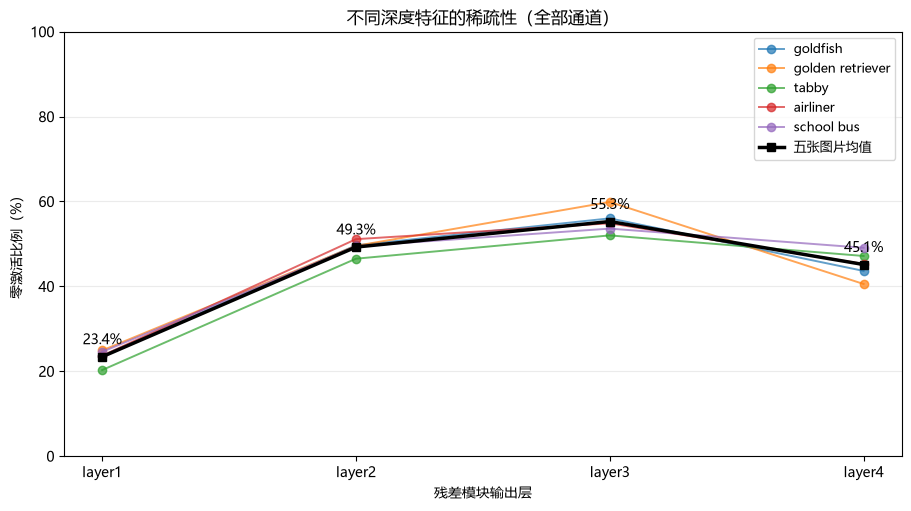

各层平均零激活比例：
 layer  mean_zero_fraction
layer1            0.234110
layer2            0.492554
layer3            0.552710
layer4            0.451419
图片和统计结果已保存至： E:\CODE\DeepLearning-exp\exp3\results\exp3B


In [6]:
sparsity = stats_df.pivot(index="sample_class", columns="layer", values="zero_fraction")
sparsity = sparsity.reindex(index=[label for label, _ in samples], columns=layer_names)

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
x = np.arange(len(layer_names))
for label, values in sparsity.iterrows():
    ax.plot(x, values.to_numpy() * 100, marker="o", linewidth=1.4, alpha=0.7,
            label=label)
mean_values = sparsity.mean(axis=0).to_numpy() * 100
ax.plot(x, mean_values, color="black", marker="s", linewidth=2.5, label="五张图片均值")
for position, value in zip(x, mean_values):
    ax.annotate(f"{value:.1f}%", (position, value), xytext=(0, 9),
                textcoords="offset points", ha="center")
ax.set_xticks(x, layer_names)
ax.set_ylim(0, 100)
ax.set_xlabel("残差模块输出层")
ax.set_ylabel("零激活比例（%）")
ax.set_title("不同深度特征的稀疏性（全部通道）")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="best", fontsize=9)
fig.savefig(RESULT_DIR / "feature_sparsity.png", dpi=180, bbox_inches="tight")
plt.show()
print("各层平均零激活比例：")
print(summary_df[["layer", "mean_zero_fraction"]].to_string(index=False))
print("图片和统计结果已保存至：", RESULT_DIR)